# Course 16: Algorithms Behind Modern AI
## Session 9: Nearest neighbours I: k-d trees, LSH and MinHash

**Goal:** build a k-d tree and count how its pruning fails as the dimension grows, build locality-sensitive hash indexes for cosine and Jaccard similarity, and find the near-duplicate documents of a corpus without comparing all pairs.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. By hand first: MinHash of two small sets
Two documents are **near-duplicates** when they share most of their pieces. Write each document as a **set** of pieces (section 5 uses every run of five characters). The **Jaccard similarity** of two sets is the size of the intersection divided by the size of the union: 1 for equal sets, 0 for sets with nothing in common.

Comparing two big sets is slow, and comparing all pairs of a million sets is impossible. **MinHash** (Broder 1997) replaces each set by a few numbers. Put all possible items in a random order. The **min-hash** of a set is its first item in that order. The key fact: two sets have the same min-hash with probability equal to their Jaccard similarity.

Do it on paper. The items are the letters a to f, and the sets are A = {a, c, d} and B = {a, d, e, f}.

* What is the Jaccard similarity of A and B?
* For each of the orders `c a f b e d`, `b d a e c f` and `e f a c d b`, find the min-hash of A and of B. In how many of the three orders are they the same?
* Why is the probability exactly the Jaccard similarity? Look only at the letters of the union, and ask which of them comes first.

In [1]:
import math, time, zlib, itertools
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse

t_start = time.time()

A, B = set("acd"), set("adef")
print(f"A = {sorted(A)}, B = {sorted(B)}")
print(f"intersection {sorted(A & B)}, union {sorted(A | B)}: Jaccard similarity {len(A & B)}/{len(A | B)} = {len(A & B) / len(A | B):.2f}")

def minhash_by_order(order, items):
    return next(x for x in order if x in items)              # the first item of the order that is in the set

n_same = 0
for order in ["cafbed", "bdaecf", "efacdb"]:
    ha, hb = minhash_by_order(order, A), minhash_by_order(order, B)
    n_same += ha == hb
    print(f"order {' '.join(order)}: min-hash of A is {ha}, min-hash of B is {hb}: {'the same' if ha == hb else 'different'}")
print(f"estimate from three orders: {n_same}/3 = {n_same / 3:.2f}")

all_orders = list(itertools.permutations("abcdef"))
n_same = sum(minhash_by_order(order, A) == minhash_by_order(order, B) for order in all_orders)
print(f"all {len(all_orders)} orders: the two min-hashes are the same in {n_same} of them, a share of {n_same / len(all_orders):.2f}")

A = ['a', 'c', 'd'], B = ['a', 'd', 'e', 'f']
intersection ['a', 'd'], union ['a', 'c', 'd', 'e', 'f']: Jaccard similarity 2/5 = 0.40
order c a f b e d: min-hash of A is c, min-hash of B is a: different
order b d a e c f: min-hash of A is d, min-hash of B is d: the same
order e f a c d b: min-hash of A is a, min-hash of B is e: different
estimate from three orders: 1/3 = 0.33
all 720 orders: the two min-hashes are the same in 288 of them, a share of 0.40


### 2. Exact search: a k-d tree, and why it stops working
The **nearest-neighbour problem**: given $n$ points and a query, find the point closest to the query. **Brute force** computes all $n$ distances, and each distance costs $d$ operations in $d$ dimensions: $O(n \cdot d)$ per query.

A **k-d tree** (Bentley 1975) is a binary search tree for points. Each node splits its points at the median of one coordinate, and the coordinates take turns. We stop when a node has at most 16 points (a leaf). The search:

1. go down to the leaf that contains the query and compute the distances there; the smallest is the best so far, $r$;
2. on the way back up, look at the other side of each split **only if** the splitting plane is closer to the query than $r$. Otherwise no point on that side can win, and the whole subtree is skipped (**pruning**).

The answer is always exact. In two dimensions the search opens only a few leaves; for a fixed, small number of dimensions the expected cost is $O(\log n)$ (Friedman, Bentley & Finkel 1977). We count the **points examined**: the points whose distance to the query was computed. Brute force examines all 20,000.

The data are synthetic: 20,000 points drawn uniformly from the unit cube, and 100 queries drawn the same way, for 2 to 64 dimensions. The last row uses points that have 64 coordinates but lie on a flat 4-dimensional sheet inside the 64-dimensional space (a rotated copy of 4-dimensional data). For each query we also compare the distances to the farthest and to the nearest point.

dimension            | points examined per query (mean) | share of the 20,000 points | farthest / nearest distance (median)
2                    |                             19.0 |                     0.10%  |   293.60


4                    |                             76.9 |                     0.38%  |    26.22


8                    |                          1,285.3 |                     6.43%  |     7.40


16                   |                         19,859.9 |                    99.30%  |     3.57


32                   |                         20,000.0 |                   100.00%  |     2.31


64                   |                         20,000.0 |                   100.00%  |     1.77


64 (a 4-dim. sheet)  |                          3,124.6 |                    15.62%  |    26.16
depth of the tree: 11 splits, so it can use at most 11 of the coordinates
  time per query,  2 dimensions: tree   0.02 ms, brute force with one NumPy call  0.44 ms
  time per query,  4 dimensions: tree   0.05 ms, brute force with one NumPy call  0.52 ms
  time per query,  8 dimensions: tree   0.71 ms, brute force with one NumPy call  0.66 ms
  time per query, 16 dimensions: tree  13.27 ms, brute force with one NumPy call  1.04 ms
  time per query, 32 dimensions: tree  15.27 ms, brute force with one NumPy call  1.62 ms
  time per query, 64 dimensions: tree  15.20 ms, brute force with one NumPy call  2.96 ms


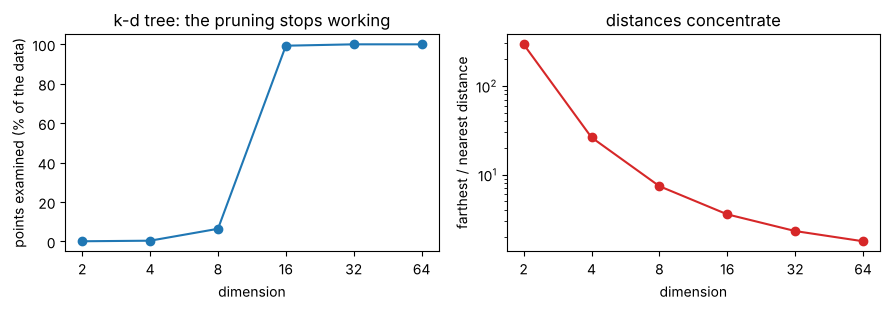

In [2]:
LEAF = 16                                                    # a leaf holds at most 16 points

def build_kdtree(X, ids, depth=0):
    # A leaf is an array of point ids. Any other node is (coordinate, split value, left child, right child).
    if len(ids) <= LEAF:
        return ids
    dim = depth % X.shape[1]                                 # the coordinates take turns
    order = ids[np.argsort(X[ids, dim], kind="stable")]
    half = len(order) // 2                                   # split at the median
    return (dim, float(X[order[half], dim]), build_kdtree(X, order[:half], depth + 1), build_kdtree(X, order[half:], depth + 1))

def kd_nearest(node, X, q, best):
    # best = [smallest squared distance so far, id of that point]. Returns the number of points examined.
    if not isinstance(node, tuple):
        d2 = ((X[node] - q) ** 2).sum(axis=1)                # the query against every point of the leaf
        j = int(d2.argmin())
        if d2[j] < best[0]:
            best[0], best[1] = float(d2[j]), int(node[j])
        return len(node)
    dim, split, left, right = node
    near, far = (left, right) if q[dim] < split else (right, left)
    n_examined = kd_nearest(near, X, q, best)
    if (q[dim] - split) ** 2 < best[0]:                      # the splitting plane is closer than the best point so far,
        n_examined += kd_nearest(far, X, q, best)            # so the other side may hold a closer point: search it too
    return n_examined

N_POINTS, N_QUERIES = 20_000, 100

def kd_experiment(X, Q):
    tree = build_kdtree(X, np.arange(len(X)))
    examined, ratio = [], []
    for q in Q:
        d2 = ((X - q) ** 2).sum(axis=1)                      # brute force gives the truth and the two extreme distances
        best = [math.inf, -1]
        examined.append(kd_nearest(tree, X, q, best))
        assert best[1] == int(d2.argmin())                   # the tree search is exact
        ratio.append(math.sqrt(d2.max() / d2.min()))
    t0 = time.perf_counter()
    for q in Q:
        kd_nearest(tree, X, q, [math.inf, -1])
    t1 = time.perf_counter()
    for q in Q:
        ((X - q) ** 2).sum(axis=1).argmin()
    t2 = time.perf_counter()
    return float(np.mean(examined)), float(np.median(ratio)), 1000 * (t1 - t0) / len(Q), 1000 * (t2 - t1) / len(Q)

DIMS = [2, 4, 8, 16, 32, 64]
kd_rows, kd_times = [], []
print("dimension            | points examined per query (mean) | share of the 20,000 points | farthest / nearest distance (median)")
for d in DIMS:
    rng = np.random.default_rng(d)
    n_ex, ratio, ms_tree, ms_brute = kd_experiment(rng.random((N_POINTS, d)), rng.random((N_QUERIES, d)))
    kd_rows.append((n_ex, ratio)); kd_times.append((d, ms_tree, ms_brute))
    print(f"{d:<20d} | {n_ex:32,.1f} | {n_ex / N_POINTS:25.2%}  | {ratio:8.2f}")

rng = np.random.default_rng(0)
sheet = np.linalg.qr(rng.normal(size=(64, 4)))[0].T          # 4 directions at right angles in 64 dimensions
n_ex, ratio, ms_tree, ms_brute = kd_experiment(rng.random((N_POINTS, 4)) @ sheet, rng.random((N_QUERIES, 4)) @ sheet)
print(f"{'64 (a 4-dim. sheet)':<20s} | {n_ex:32,.1f} | {n_ex / N_POINTS:25.2%}  | {ratio:8.2f}")
print(f"depth of the tree: {math.ceil(math.log2(N_POINTS / LEAF))} splits, so it can use at most {math.ceil(math.log2(N_POINTS / LEAF))} of the coordinates")
for d, ms_tree, ms_brute in kd_times:
    print(f"  time per query, {d:2d} dimensions: tree {ms_tree:6.2f} ms, brute force with one NumPy call {ms_brute:5.2f} ms")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot(DIMS, [100 * r[0] / N_POINTS for r in kd_rows], "o-")
ax[0].set_xscale("log", base=2); ax[0].set_xticks(DIMS); ax[0].set_xticklabels(DIMS)
ax[0].set_xlabel("dimension"); ax[0].set_ylabel("points examined (% of the data)"); ax[0].set_title("k-d tree: the pruning stops working")
ax[1].plot(DIMS, [r[1] for r in kd_rows], "o-", color="tab:red")
ax[1].set_xscale("log", base=2); ax[1].set_yscale("log"); ax[1].set_xticks(DIMS); ax[1].set_xticklabels(DIMS)
ax[1].set_xlabel("dimension"); ax[1].set_ylabel("farthest / nearest distance"); ax[1].set_title("distances concentrate")
plt.tight_layout(); plt.show()

### 3. Locality-sensitive hashing for cosine similarity
If exact search must look at almost every point, we give up exactness. **Locality-sensitive hashing** (LSH; Indyk & Motwani 1998) uses hash functions under which **near points collide more often than far points**, the opposite of what we wanted from a hash table in session 2.

For cosine similarity the hash is one **random hyperplane** through the origin (Charikar 2002): draw a random vector $r$, and the hash bit of $x$ is 1 if $r \cdot x > 0$, else 0. Two vectors get different bits only when the hyperplane passes between them, so for an angle $\theta$ between them

$$P(\text{same bit}) = 1 - \theta / \pi .$$

Angle 0 gives 1, a right angle gives 0.5, opposite vectors give 0. The cell builds pairs of unit vectors at chosen angles in 64 dimensions and counts the equal bits over 10,000 random hyperplanes.

One bit separates near from far only weakly (0.9 against 0.5). So we **amplify**:

* **AND:** one table uses $k$ bits as the bucket key. Two vectors share a bucket with probability $p^k$, which removes most far points, but also many near ones.
* **OR:** we build $L$ tables with different hyperplanes, and a point becomes a **candidate** if it shares a bucket with the query in at least one table: probability $1 - (1 - p^k)^L$.

Plotted against similarity this is an **S-curve**: close to 0 for far points, close to 1 for near points, with a step in between that $k$ and $L$ move.

angle (degrees) | cosine | equal bits of 10,000 | measured rate | formula 1 - angle/180
             10 |  0.985 |                9,464 |        0.9464 | 0.9444
             20 |  0.940 |                8,866 |        0.8866 | 0.8889
             30 |  0.866 |                8,351 |        0.8351 | 0.8333
             45 |  0.707 |                7,440 |        0.7440 | 0.7500
             60 |  0.500 |                6,712 |        0.6712 | 0.6667
             90 |  0.000 |                5,078 |        0.5078 | 0.5000
            120 | -0.500 |                3,310 |        0.3310 | 0.3333
            150 | -0.866 |                1,614 |        0.1614 | 0.1667


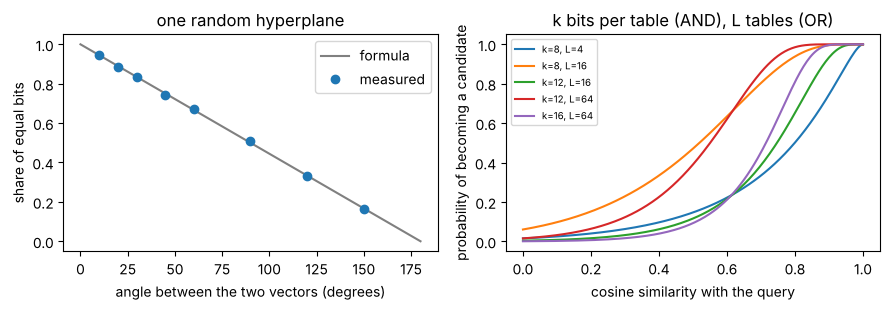

In [3]:
D_LSH = 64
rng = np.random.default_rng(3)

def unit(v):
    return v / np.linalg.norm(v, axis=-1, keepdims=True)

def pair_at_angle(theta, rng):
    x = unit(rng.normal(size=D_LSH))
    u = rng.normal(size=D_LSH); u = unit(u - (u @ x) * x)     # a unit vector at a right angle to x
    return x, math.cos(theta) * x + math.sin(theta) * u

N_PLANES = 10_000
planes = rng.normal(size=(N_PLANES, D_LSH))
ANGLES = [10, 20, 30, 45, 60, 90, 120, 150]
measured = []
print("angle (degrees) | cosine | equal bits of 10,000 | measured rate | formula 1 - angle/180")
for deg in ANGLES:
    x, y = pair_at_angle(math.radians(deg), rng)
    n_equal = int(((planes @ x > 0) == (planes @ y > 0)).sum())
    measured.append(n_equal / N_PLANES)
    print(f"{deg:15d} | {math.cos(math.radians(deg)):6.3f} | {n_equal:20,d} | {n_equal / N_PLANES:13.4f} | {1 - deg / 180:.4f}")

def candidate_probability(cosine, k, L):
    p = 1 - np.arccos(np.clip(cosine, -1, 1)) / math.pi      # one bit is equal with this probability
    return 1 - (1 - p ** k) ** L

SETTINGS = [(8, 4), (8, 16), (12, 16), (12, 64), (16, 64)]   # (k bits per table, L tables)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].plot([0, 180], [1, 0], color="gray", label="formula")
ax[0].plot(ANGLES, measured, "o", label="measured")
ax[0].set_xlabel("angle between the two vectors (degrees)"); ax[0].set_ylabel("share of equal bits")
ax[0].set_title("one random hyperplane"); ax[0].legend()
cos_grid = np.linspace(0, 1, 201)
for k, L in SETTINGS:
    ax[1].plot(cos_grid, candidate_probability(cos_grid, k, L), label=f"k={k}, L={L}")
ax[1].set_xlabel("cosine similarity with the query"); ax[1].set_ylabel("probability of becoming a candidate")
ax[1].set_title("k bits per table (AND), L tables (OR)"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

**An index on 20,000 vectors.** The data are synthetic: 200 query vectors, and for each query ten **planted neighbours** with cosine similarity 0.95, 0.91, 0.87, … down to 0.59. The other 18,000 vectors point in random directions; in 64 dimensions random directions are almost at right angles to the query (cosine close to 0). The exact top 10 of every query, by brute force over all 20,000 vectors, is our ground truth.

One table is a dictionary from a $k$-bit key to the list of vectors with that key (session 2). To answer a query we compute its key in each of the $L$ tables, collect the vectors in those buckets (the **candidates**), compute the exact similarity only for them, and return the best 10. Two numbers describe the result:

* **recall@10:** how many of the true top 10 are among the 10 returned, as a share;
* **work:** the number of candidates examined, plus the $k \cdot L$ dot products that hash the query.

The formula of the S-curve predicts both, because we know the similarity of the query to every vector: the average of $1 - (1 - p^k)^L$ over the true neighbours is the expected recall, and the sum over all 20,000 vectors is the expected number of candidates.

In [4]:
N_LSH, N_Q, N_PLANT = 20_000, 200, 10
rng = np.random.default_rng(4)
queries = unit(rng.normal(size=(N_Q, D_LSH)))
plant_cos = 0.95 - 0.04 * np.arange(N_PLANT)                 # 0.95, 0.91, ..., 0.59
noise = rng.normal(size=(N_Q, N_PLANT, D_LSH))
noise = unit(noise - (noise @ queries[:, :, None]) * queries[:, None, :])        # at a right angle to the query
planted = plant_cos[None, :, None] * queries[:, None, :] + np.sqrt(1 - plant_cos ** 2)[None, :, None] * noise
data = np.concatenate([planted.reshape(-1, D_LSH), unit(rng.normal(size=(N_LSH - N_Q * N_PLANT, D_LSH)))])
data = data[rng.permutation(N_LSH)]                          # mix the planted vectors among the others

sims = queries @ data.T                                      # brute force: 200 x 20,000 dot products
truth = np.argsort(-sims, axis=1)[:, :10]
true_sims = np.take_along_axis(sims, truth, axis=1)
others = np.sort(sims, axis=1)[:, :-10]
print(f"data: {N_LSH:,d} unit vectors in {D_LSH} dimensions, {N_Q} queries")
print(f"cosine of the true top 10 (mean over the queries): " + " ".join(f"{c:.2f}" for c in true_sims.mean(axis=0)))
print(f"cosine of the other 19,990 vectors: mean {others.mean():.3f}, standard deviation {others.std():.3f}, largest {others.max():.3f}")

def build_lsh(data, k, L, rng):
    planes = rng.normal(size=(L, k, data.shape[1]))          # k random hyperplanes for each of the L tables
    weights = 1 << np.arange(k)                              # turns k bits into one integer key
    tables = []
    for l in range(L):
        keys = ((data @ planes[l].T > 0) * weights).sum(axis=1)
        table = {}                                           # key -> list of the vectors in that bucket
        for i, key in enumerate(keys.tolist()):
            table.setdefault(key, []).append(i)
        tables.append(table)
    return planes, weights, tables

def lsh_candidates(q, planes, weights, tables):
    keys = ((planes @ q > 0) * weights).sum(axis=1)          # the query's key in each table
    found = set()
    for table, key in zip(tables, keys.tolist()):
        found.update(table.get(key, ()))
    return np.array(sorted(found), dtype=np.int64)

found_by_rank = {}
print("\n k |  L | hash bits per query | candidates per query (formula) | work: bits + candidates | share of brute force | recall@10 (formula)")
for k, L in SETTINGS:
    t0 = time.perf_counter()
    planes_kl, weights, tables = build_lsh(data, k, L, np.random.default_rng(100 * k + L))
    t1 = time.perf_counter()
    n_cand, hits = 0, np.zeros(10, dtype=int)
    for qi in range(N_Q):
        cand = lsh_candidates(queries[qi], planes_kl, weights, tables)
        n_cand += len(cand)
        if len(cand):
            best = cand[np.argsort(-(data[cand] @ queries[qi]))[:10]]                # exact similarity for the candidates only
            hits += np.isin(truth[qi], best)                 # which of the true top 10 were returned
    t2 = time.perf_counter()
    expected_cand = candidate_probability(sims, k, L).sum(axis=1).mean()             # the S-curve for every (query, vector) pair
    expected_recall = candidate_probability(true_sims, k, L).mean()
    found_by_rank[(k, L)] = hits
    work = k * L + n_cand / N_Q
    print(f"{k:2d} | {L:2d} | {k * L:19,d} | {n_cand / N_Q:12,.1f} ({expected_cand:8,.1f})         | {work:23,.1f} | {work / N_LSH:19.2%}  | {hits.sum() / (10 * N_Q):.3f} ({expected_recall:.3f})")
    print(f"     time: build {t1 - t0:.2f} s, {N_Q} queries {t2 - t1:.2f} s")
print(f"brute force: {N_LSH:,d} dot products per query, recall 1.000")
print(f"\nin how many of the {N_Q} queries was the true neighbour with this cosine similarity returned?")
print(" k |  L | " + " ".join(f"{c:5.2f}" for c in plant_cos))
for (k, L), hits in found_by_rank.items():
    print(f"{k:2d} | {L:2d} | " + " ".join(f"{int(h):5d}" for h in hits))
print(f"\nmemory of the index: one id per vector in each table, so L = 64 tables hold {64 * N_LSH:,d} ids; the data hold {N_LSH * D_LSH:,d} numbers")

data: 20,000 unit vectors in 64 dimensions, 200 queries
cosine of the true top 10 (mean over the queries): 0.95 0.91 0.87 0.83 0.79 0.75 0.71 0.67 0.63 0.59
cosine of the other 19,990 vectors: mean 0.000, standard deviation 0.125, largest 0.579

 k |  L | hash bits per query | candidates per query (formula) | work: bits + candidates | share of brute force | recall@10 (formula)
 8 |  4 |                  32 |        372.5 (   372.9)         |                   404.5 |               2.02%  | 0.494 (0.490)
     time: build 0.01 s, 200 queries 0.03 s


 8 | 16 |                 128 |      1,420.4 ( 1,423.9)         |                 1,548.4 |               7.74%  | 0.857 (0.863)
     time: build 0.08 s, 200 queries 0.10 s


12 | 16 |                 192 |        122.6 (   121.6)         |                   314.6 |               1.57%  | 0.582 (0.588)
     time: build 0.32 s, 200 queries 0.02 s


12 | 64 |                 768 |        457.7 (   463.5)         |                 1,225.7 |               6.13%  | 0.896 (0.888)
     time: build 0.57 s, 200 queries 0.08 s


16 | 64 |               1,024 |         45.8 (    46.1)         |                 1,069.8 |               5.35%  | 0.668 (0.659)
     time: build 1.26 s, 200 queries 0.04 s
brute force: 20,000 dot products per query, recall 1.000

in how many of the 200 queries was the true neighbour with this cosine similarity returned?
 k |  L |  0.95  0.91  0.87  0.83  0.79  0.75  0.71  0.67  0.63  0.59
 8 |  4 |   183   150   133   115   100    85    62    62    50    48
 8 | 16 |   200   200   197   192   180   175   159   155   134   122
12 | 16 |   199   193   168   144   122   105    81    56    53    43
12 | 64 |   200   200   200   200   198   192   181   160   143   118
16 | 64 |   200   200   199   186   159   129    98    69    54    42

memory of the index: one id per vector in each table, so L = 64 tables hold 1,280,000 ids; the data hold 1,280,000 numbers


### 4. MinHash with real hash functions, and banding
Section 1 used random orders of all items. With millions of different items we cannot store an order, so we **simulate** one with a hash function. Give every item an integer id $x$, choose a prime $p$ larger than every id, and draw $a$ and $b$ at random:

$$h(x) = (a \cdot x + b) \bmod p .$$

This is the universal hash family of session 2. The value $h(x)$ plays the role of the item's position in the order, and the min-hash of a set is the smallest $h(x)$ over its items. With $K$ different pairs $(a, b)$ we get $K$ min-hashes: the set's **signature**. The share of positions where two signatures agree estimates the Jaccard similarity $J$. Each position agrees with probability (about) $J$, so the estimate has standard error $\sqrt{J(1 - J)/K}$: four times more hash functions halve the error.

The test sets are synthetic: random integer ids, built so that the union has 100 items and the true Jaccard similarity is exactly 0.1, 0.2, …, 0.9.

**Banding** (Leskovec, Rajaraman & Ullman 2020, chapter 3) turns signatures into an index, with the same AND and OR as in section 3. Cut the signature into $b$ bands of $r$ rows. Two sets are a **candidate pair** if they agree on all $r$ rows of at least one band:

$$P(\text{candidate}) = 1 - (1 - s^r)^b \quad \text{for Jaccard similarity } s .$$

Each band is one hash table: the key is the band's $r$ numbers, so sets that agree on a band meet in a bucket and nothing else is compared. The step of this S-curve is near $(1/b)^{1/r}$.

true Jaccard | mean estimate | RMS error (formula) | candidate pairs of 500: 50 x 2 (formula) | 20 x 5 (formula) | 10 x 10 (formula)
         0.1 |         0.100 | 0.030 (0.030)       |  190 (197.5)   |    0 (  0.1)   |    0 (  0.0)   |
         0.2 |         0.199 | 0.043 (0.040)       |  431 (435.1)   |    2 (  3.2)   |    0 (  0.0)   |


         0.3 |         0.299 | 0.045 (0.046)       |  496 (495.5)   |   31 ( 23.7)   |    0 (  0.0)   |
         0.4 |         0.401 | 0.050 (0.049)       |  500 (499.9)   |   93 ( 93.0)   |    0 (  0.5)   |
         0.5 |         0.501 | 0.049 (0.050)       |  500 (500.0)   |  237 (235.0)   |    4 (  4.9)   |


         0.6 |         0.599 | 0.052 (0.049)       |  500 (500.0)   |  401 (401.0)   |   26 ( 29.4)   |
         0.7 |         0.700 | 0.048 (0.046)       |  500 (500.0)   |  490 (487.4)   |  125 (124.6)   |
         0.8 |         0.801 | 0.040 (0.040)       |  500 (500.0)   |  499 (499.8)   |  341 (339.4)   |


         0.9 |         0.900 | 0.029 (0.030)       |  500 (500.0)   |  500 (500.0)   |  492 (493.1)   |



signature length K, 300 pairs with Jaccard similarity 0.5:
  K =   16: RMS error of the estimate 0.1214, formula 0.1250
  K =   64: RMS error of the estimate 0.0645, formula 0.0625
  K =  256: RMS error of the estimate 0.0305, formula 0.0312
  K = 1024: RMS error of the estimate 0.0163, formula 0.0156
banding 50 x 2: the step of the S-curve is near (1/50)^(1/2) = 0.141
banding 20 x 5: the step of the S-curve is near (1/20)^(1/5) = 0.549
banding 10 x 10: the step of the S-curve is near (1/10)^(1/10) = 0.794


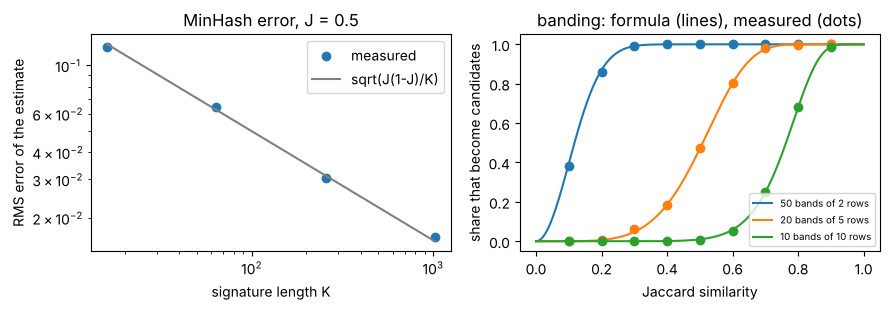

In [5]:
P_PRIME = 2_147_483_647                                      # the prime 2^31 - 1; a * x + b stays below 2^63

def make_hash_functions(K, rng):
    return rng.integers(1, P_PRIME, size=K, dtype=np.int64), rng.integers(0, P_PRIME, size=K, dtype=np.int64)

def signature(ids, a, b):
    # ids: integer ids of the set's items. One row per hash function, then the smallest value of each row.
    return ((a[:, None] * ids[None, :] + b[:, None]) % P_PRIME).min(axis=1)

def pair_with_jaccard(n_shared, rng, union=100):
    ids = rng.choice(1_000_000, size=union, replace=False).astype(np.int64)
    n_own = (union - n_shared) // 2                          # items that only one of the two sets has
    return ids[:n_shared + n_own], np.concatenate([ids[:n_shared], ids[n_shared + n_own:]])

rng = np.random.default_rng(5)
a100, b100 = make_hash_functions(100, rng)
N_PAIRS = 500
BANDINGS = [(50, 2), (20, 5), (10, 10)]                      # (b bands, r rows), all with b * r = 100
JACCARDS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
band_counts = {br: [] for br in BANDINGS}
print("true Jaccard | mean estimate | RMS error (formula) | candidate pairs of 500: 50 x 2 (formula) | 20 x 5 (formula) | 10 x 10 (formula)")
for jac in JACCARDS:
    estimates, n_cand = [], {br: 0 for br in BANDINGS}
    for _ in range(N_PAIRS):
        s1, s2 = pair_with_jaccard(round(100 * jac), rng)
        equal = signature(s1, a100, b100) == signature(s2, a100, b100)
        estimates.append(equal.mean())
        for b, r in BANDINGS:
            n_cand[(b, r)] += bool(equal.reshape(b, r).all(axis=1).any())            # some band agrees on all its rows
    estimates = np.array(estimates)
    line = f"{jac:12.1f} | {estimates.mean():13.3f} | {math.sqrt(((estimates - jac) ** 2).mean()):.3f} ({math.sqrt(jac * (1 - jac) / 100):.3f})       |"
    for b, r in BANDINGS:
        band_counts[(b, r)].append(n_cand[(b, r)])
        line += f" {n_cand[(b, r)]:4d} ({N_PAIRS * (1 - (1 - jac ** r) ** b):5.1f})   |"
    print(line)

a_long, b_long = make_hash_functions(1024, rng)
agree = []
for _ in range(300):
    s1, s2 = pair_with_jaccard(50, rng)                      # true Jaccard similarity 0.5
    agree.append(signature(s1, a_long, b_long) == signature(s2, a_long, b_long))
agree = np.array(agree)
LENGTHS = [16, 64, 256, 1024]
rms = [math.sqrt(((agree[:, :K].mean(axis=1) - 0.5) ** 2).mean()) for K in LENGTHS]
print("\nsignature length K, 300 pairs with Jaccard similarity 0.5:")
for K, e in zip(LENGTHS, rms):
    print(f"  K = {K:4d}: RMS error of the estimate {e:.4f}, formula {math.sqrt(0.25 / K):.4f}")
for b, r in BANDINGS:
    print(f"banding {b} x {r}: the step of the S-curve is near (1/{b})^(1/{r}) = {(1 / b) ** (1 / r):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].loglog(LENGTHS, rms, "o", label="measured")
ax[0].loglog(LENGTHS, [math.sqrt(0.25 / K) for K in LENGTHS], color="gray", label="sqrt(J(1-J)/K)")
ax[0].set_xlabel("signature length K"); ax[0].set_ylabel("RMS error of the estimate"); ax[0].set_title("MinHash error, J = 0.5"); ax[0].legend()
s_grid = np.linspace(0, 1, 201)
for (b, r), colour in zip(BANDINGS, ["tab:blue", "tab:orange", "tab:green"]):
    ax[1].plot(s_grid, 1 - (1 - s_grid ** r) ** b, color=colour, label=f"{b} bands of {r} rows")
    ax[1].plot(JACCARDS, [c / N_PAIRS for c in band_counts[(b, r)]], "o", color=colour)
ax[1].set_xlabel("Jaccard similarity"); ax[1].set_ylabel("share that become candidates")
ax[1].set_title("banding: formula (lines), measured (dots)"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

### 5. Near-duplicates in a corpus
Now the real task. The corpus is **synthetic**: 2,000 short documents of about 40 words, made by filling sentence patterns with words from small lists written for this notebook.

* 1,600 documents are written independently. One in five of them also carries one of eight footer lines, as pages of the same website do.
* 400 documents are **planted near-duplicates** of 200 of the others (one to three copies each), made in three ways: small edits (each word is replaced with probability 0.08), an added line of boilerplate at the start or the end, or both.

Each document becomes the set of its **shingles**: every run of five characters. A fixed 32-bit hash (`zlib.crc32`) turns a shingle into an integer id. Python's own `hash()` would give different ids in every run (session 2).

This corpus is small enough to compute the **exact** Jaccard similarity of all 1,999,000 pairs with one sparse matrix product. That is our ground truth, and a real corpus of millions of documents could not afford it. We call a pair a near-duplicate when its Jaccard similarity is at least 0.6.

In [6]:
PEOPLE = "farmer teacher doctor student driver fisherman weaver nurse engineer shopkeeper boatman potter tailor librarian postman carpenter".split()
ADJECTIVES = "old young quiet busy tired happy careful curious patient clever honest friendly".split()
VERBS = "carried repaired counted painted washed sold bought found measured cleaned packed opened moved checked".split()
OBJECTS = "baskets lanterns bicycles notebooks umbrellas ropes nets bricks mangoes radios kites ledgers blankets seedlings clocks bottles".split()
PLACES = "river market bridge school station orchard workshop harbour clinic library bazaar courtyard warehouse crossroads".split()
TIMES = ["before sunrise", "at noon", "after the rain", "in the evening", "on friday", "during the flood", "late at night",
         "every winter", "last week", "at harvest time"]
NUMBERS = "two three five seven nine twelve twenty forty".split()
PATTERNS_DOC = ["the {adj} {person} {verb} the {obj} near the {place} {time}",
                "{time} the {person} from the {place} {verb} {num} {obj}",
                "nobody at the {place} knew why the {person} {verb} the {obj}",
                "the {person} and the {other} {verb} {num} {obj} beside the {place}",
                "one {adj} {person} {verb} the {obj} and walked to the {place}"]
BOILERPLATE = ["shared from the village news page", "read the full story on our website", "all rights reserved by the district gazette",
               "sent from a mobile phone", "click here to subscribe to the weekly letter", "this notice was posted by the admin",
               "printed copies are available at the office", "forwarded as received"]
ALL_WORDS = sorted(set(PEOPLE + ADJECTIVES + VERBS + OBJECTS + PLACES + NUMBERS))

rng = np.random.default_rng(6)
pick = lambda words: words[int(rng.integers(len(words)))]

def make_document():
    return ". ".join(pick(PATTERNS_DOC).format(adj=pick(ADJECTIVES), person=pick(PEOPLE), other=pick(PEOPLE), verb=pick(VERBS),
                                               obj=pick(OBJECTS), place=pick(PLACES), time=pick(TIMES), num=pick(NUMBERS)) for _ in range(4))

def small_edits(doc, rate=0.08):
    return " ".join(pick(ALL_WORDS) if rng.random() < rate else w for w in doc.split())

def add_boilerplate(doc):
    line = pick(BOILERPLATE)
    return line + ". " + doc if rng.random() < 0.5 else doc + ". " + line

N_BASE = 1600
docs = [make_document() for _ in range(N_BASE)]
for i in range(0, N_BASE, 5):                                # one document in five carries a footer
    docs[i] = docs[i] + ". " + pick(BOILERPLATE)
group = list(range(N_BASE))                                  # group[i]: the planted group of document i
sources = rng.choice(N_BASE, size=200, replace=False).tolist()
copies_per_source = [1, 2, 3] * 66 + [2, 2]                  # 400 copies in total
kinds = ["small edits", "boilerplate", "both"]
examples = {}
for n, (s, n_copies) in enumerate(zip(sources, copies_per_source)):
    for c in range(n_copies):
        kind = kinds[(n + c) % 3]
        copy = docs[s]
        if kind != "boilerplate":
            copy = small_edits(copy)
        if kind != "small edits":
            copy = add_boilerplate(copy)
        examples.setdefault(kind, (docs[s], copy))
        docs.append(copy); group.append(s)
order = rng.permutation(len(docs)).tolist()                  # shuffle, so that copies are not next to their source
docs, group = [docs[i] for i in order], [group[i] for i in order]
N_DOCS = len(docs)

def shingles(doc, size=5):
    return {doc[i:i + size] for i in range(len(doc) - size + 1)}

shingle_sets = [shingles(doc) for doc in docs]
id_arrays = [np.array(sorted({zlib.crc32(s.encode("utf-8")) % P_PRIME for s in sh}), dtype=np.int64) for sh in shingle_sets]
planted_pairs = {(i, j) for i in range(N_DOCS) for j in range(i + 1, N_DOCS) if group[i] == group[j]}

print(f"{N_DOCS:,d} documents, {np.mean([len(doc.split()) for doc in docs]):.1f} words and {np.mean([len(s) for s in shingle_sets]):.0f} different shingles per document on average")
print(f"all pairs: {N_DOCS * (N_DOCS - 1) // 2:,d};  planted near-duplicate pairs: {len(planted_pairs):,d}, in {len(sources)} groups")
src, copy = examples["both"]
print("a source: " + src)
print("its copy (small edits and boilerplate): " + copy)

# ground truth: the exact Jaccard similarity of every pair, from one sparse matrix product
column = {}
rows_idx, cols_idx = [], []
for i, sh in enumerate(shingle_sets):
    for s in sorted(sh):
        rows_idx.append(i); cols_idx.append(column.setdefault(s, len(column)))
t0 = time.perf_counter()
M = sparse.csr_matrix((np.ones(len(rows_idx), dtype=np.int32), (rows_idx, cols_idx)), shape=(N_DOCS, len(column)))
common = (M @ M.T).toarray()                                 # common[i, j]: the number of shingles that i and j share
sizes = common.diagonal()
jaccard = common / (sizes[:, None] + sizes[None, :] - common)
t_brute = time.perf_counter() - t0
upper = np.triu(np.ones((N_DOCS, N_DOCS), dtype=bool), k=1)   # each pair once
THRESHOLD = 0.6
true_pairs = {(int(i), int(j)) for i, j in zip(*np.nonzero((jaccard >= THRESHOLD) & upper))}
planted_j = np.array([jaccard[i, j] for i, j in sorted(planted_pairs)])
print(f"\n{len(column):,d} different shingles in the corpus")
print(f"exact Jaccard similarity of all pairs: median {np.median(jaccard[upper]):.3f}, 99.9th percentile {np.quantile(jaccard[upper], 0.999):.3f}")
print(f"planted pairs: Jaccard similarity from {planted_j.min():.2f} to {planted_j.max():.2f}, median {np.median(planted_j):.2f}; {int((planted_j >= THRESHOLD).sum())} of {len(planted_j)} are at least {THRESHOLD}")
print(f"pairs with Jaccard similarity at least {THRESHOLD}: {len(true_pairs):,d}, of which {len(true_pairs & planted_pairs):,d} are planted")
print(f"  time for the exact similarity of all pairs (sparse matrix product): {t_brute:.2f} s")

2,000 documents, 46.1 words and 228 different shingles per document on average
all pairs: 1,999,000;  planted near-duplicate pairs: 666, in 200 groups
a source: the fisherman and the carpenter washed seven baskets beside the market. nobody at the school knew why the driver checked the bottles. nobody at the harbour knew why the student repaired the radios. one honest driver moved the ledgers and walked to the courtyard. read the full story on our website
its copy (small edits and boilerplate): sent from a mobile phone. the fisherman and the carpenter washed seven baskets beside the market. nobody at the school knew weaver the driver checked the bottles. nobody at the harbour twenty why radios student repaired the radios. one honest driver moved the ledgers and walked to the courtyard. bridge the full story on radios website



4,810 different shingles in the corpus
exact Jaccard similarity of all pairs: median 0.153, 99.9th percentile 0.340
planted pairs: Jaccard similarity from 0.39 to 1.00, median 0.74; 574 of 666 are at least 0.6
pairs with Jaccard similarity at least 0.6: 574, of which 574 are planted
  time for the exact similarity of all pairs (sparse matrix product): 0.69 s


**The pipeline that scales.** Compute a signature of 100 min-hashes per document. Cut it into 20 bands of 5 rows, and use one dictionary per band. Only documents that meet in a bucket become candidate pairs; for those we compute the exact Jaccard similarity and keep the pairs with at least 0.6. The formula $1 - (1 - s^5)^{20}$, applied to the exact similarity of every pair, predicts how many candidates we should get and how many true pairs we should find.

Near-duplicates come in groups: if A is a copy of B and B is a copy of C, all three belong together, even when A and C are less similar than 0.6. The verified pairs are the edges of a graph, and its connected components are the groups. **Union–find** builds them in almost linear time: with union by size and path compression, $m$ operations on $n$ items cost $O(m \, \alpha(n))$, where $\alpha$ is the inverse Ackermann function, at most 4 for any input you will ever see (Tarjan 1975).

We report precision and recall twice: for the verified pairs, and for all pairs of documents that end up in the same group.

In [7]:
K_SIG, N_BANDS, N_ROWS = 100, 20, 5
rng = np.random.default_rng(7)
a_sig, b_sig = make_hash_functions(K_SIG, rng)
t0 = time.perf_counter()
signatures = np.array([signature(ids, a_sig, b_sig) for ids in id_arrays])       # 2,000 x 100

def candidate_pairs(signatures, n_bands, n_rows):
    pairs = set()
    rows = signatures.tolist()
    for band in range(n_bands):
        buckets = {}                                         # one hash table per band
        for i, row in enumerate(rows):
            buckets.setdefault(tuple(row[band * n_rows:(band + 1) * n_rows]), []).append(i)
        for members in buckets.values():
            pairs.update(itertools.combinations(members, 2)) # every pair inside a bucket
    return sorted(pairs)

candidates = candidate_pairs(signatures, N_BANDS, N_ROWS)
verified = [(i, j) for i, j in candidates
            if len(shingle_sets[i] & shingle_sets[j]) / len(shingle_sets[i] | shingle_sets[j]) >= THRESHOLD]     # the exact check
t_lsh = time.perf_counter() - t0

n_all = N_DOCS * (N_DOCS - 1) // 2
s_curve = 1 - (1 - jaccard ** N_ROWS) ** N_BANDS             # the formula, for the exact similarity of every pair
found = set(verified)
print(f"signatures: {K_SIG} min-hashes per document; {N_BANDS} bands of {N_ROWS} rows")
print(f"candidate pairs: {len(candidates):,d} of {n_all:,d} ({len(candidates) / n_all:.3%}); the formula predicts {s_curve[upper].sum():,.0f}")
print(f"exact checks: {len(candidates):,d} instead of {n_all:,d}; pairs that pass (Jaccard at least {THRESHOLD}): {len(verified):,d}")
print(f"recall against the exact search: {len(found & true_pairs):,d} of {len(true_pairs):,d} = {len(found & true_pairs) / len(true_pairs):.3f}; "
      f"the formula predicts {np.mean([s_curve[i, j] for i, j in sorted(true_pairs)]):.3f}")
missed = sorted(true_pairs - found)
print(f"missed pairs: {len(missed)}, with Jaccard similarity from {min(jaccard[i, j] for i, j in missed):.2f} to {max(jaccard[i, j] for i, j in missed):.2f}"
      if missed else "missed pairs: 0")
print(f"  time for signatures, banding and exact checks: {t_lsh:.2f} s")

again = []
for seed in range(100, 110):                                 # ten more indexes, each with its own 100 hash functions
    a_r, b_r = make_hash_functions(K_SIG, np.random.default_rng(seed))
    pairs = candidate_pairs(np.array([signature(ids, a_r, b_r) for ids in id_arrays]), N_BANDS, N_ROWS)
    again.append((len(pairs), len(true_pairs.intersection(pairs))))
print(f"ten more indexes with other hash functions: candidate pairs from {min(a for a, h in again):,d} to {max(a for a, h in again):,d} "
      f"(mean {np.mean([a for a, h in again]):,.0f}); true pairs found from {min(h for a, h in again)} to {max(h for a, h in again)} of {len(true_pairs)}")

class UnionFind:
    def __init__(self, n):
        self.parent, self.size = list(range(n)), [1] * n
    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]     # path compression: point to the grandparent
            x = self.parent[x]
        return x
    def union(self, x, y):
        x, y = self.find(x), self.find(y)
        if x == y:
            return False
        if self.size[x] < self.size[y]:
            x, y = y, x
        self.parent[y] = x; self.size[x] += self.size[y]     # union by size: the smaller tree goes under the larger
        return True

uf = UnionFind(N_DOCS)
n_merges = sum(uf.union(i, j) for i, j in verified)
members = {}
for i in range(N_DOCS):
    members.setdefault(uf.find(i), []).append(i)
found_groups = [m for m in members.values() if len(m) > 1]
group_pairs = {pair for m in found_groups for pair in itertools.combinations(m, 2)}

def precision_recall(pairs):
    hit = len(pairs & planted_pairs)
    return f"precision {hit:,d}/{len(pairs):,d} = {hit / len(pairs):.3f}, recall {hit:,d}/{len(planted_pairs):,d} = {hit / len(planted_pairs):.3f}"

sizes_found = sorted(len(m) for m in found_groups)
print(f"\nunion-find: {len(verified):,d} verified pairs gave {n_merges:,d} merges and {len(found_groups)} groups of two or more documents "
      f"(sizes {sizes_found[0]} to {sizes_found[-1]}); {N_DOCS - sum(sizes_found):,d} documents have no near-duplicate")
print("against the planted truth:")
print(f"  verified pairs:           {precision_recall(found)}")
print(f"  pairs in the same group:  {precision_recall(group_pairs)}")
print(f"  exact search, all pairs:  {precision_recall(true_pairs)}")
keep = len(members)
print(f"keeping one document per group leaves {keep:,d} of {N_DOCS:,d} documents")

signatures: 100 min-hashes per document; 20 bands of 5 rows
candidate pairs: 7,591 of 1,999,000 (0.380%); the formula predicts 8,801
exact checks: 7,591 instead of 1,999,000; pairs that pass (Jaccard at least 0.6): 559
recall against the exact search: 559 of 574 = 0.974; the formula predicts 0.970
missed pairs: 15, with Jaccard similarity from 0.60 to 0.70
  time for signatures, banding and exact checks: 0.53 s


ten more indexes with other hash functions: candidate pairs from 4,475 to 11,567 (mean 6,990); true pairs found from 550 to 567 of 574

union-find: 559 verified pairs gave 380 merges and 197 groups of two or more documents (sizes 2 to 4); 1,423 documents have no near-duplicate
against the planted truth:
  verified pairs:           precision 559/559 = 1.000, recall 559/666 = 0.839
  pairs in the same group:  precision 616/616 = 1.000, recall 616/666 = 0.925
  exact search, all pairs:  precision 574/574 = 1.000, recall 574/666 = 0.862
keeping one document per group leaves 1,620 of 2,000 documents


### 6. The same with a library (NOT RUN here)
`datasketch` is an open-source library with MinHash and a banding index (`MinHashLSH`). The cell follows its documentation as checked in November 2026. `params=(20, 5)` sets the bands and rows by hand; with `threshold=0.6` instead, the library chooses them for you.

In [ ]:
# NOT RUN: needs `pip install datasketch` (a library that is not installed here).
from datasketch import MinHash, MinHashLSH

def sketch(shingle_set, num_perm=100):
    m = MinHash(num_perm=num_perm)                           # 100 hash functions
    for s in shingle_set:
        m.update(s.encode("utf8"))
    return m

sketches = [sketch(sh) for sh in shingle_sets]
lsh = MinHashLSH(num_perm=100, params=(20, 5))               # 20 bands of 5 rows, as in section 5
for i, m in enumerate(sketches):
    lsh.insert(f"doc{i}", m)

print("estimated Jaccard similarity of documents 0 and 1:", sketches[0].jaccard(sketches[1]))
print("candidates for document 0:", lsh.query(sketches[0]))  # keys of the documents that share a band with it; check them exactly

### 7. Exercises

In [8]:
# TODO: SimHash (Charikar 2002; Manku, Jain & Das Sarma 2007). A document gets one 64-bit fingerprint:
#   1. hash every shingle to 64 bits, for example int.from_bytes(hashlib.blake2b(s.encode(), digest_size=8).digest(), "big");
#   2. for each of the 64 bit positions add +1 if the shingle's bit is 1 and -1 if it is 0, over all shingles of the document;
#   3. the fingerprint has a 1 wherever the sum is positive.
# This is the random-hyperplane hash of section 3 applied to the document's shingle counts. Near-duplicates differ in few bits.
# Write simhash(shingle_set), compute the fingerprints of all documents, and count the Hamming distance (the number of
# different bits: bin(x ^ y).count("1")) for the planted pairs and for 2,000 random pairs. Which distance separates them best?
def simhash(shingle_set):
    return None          # replace with your code: return an integer below 2**64

r = simhash(shingle_sets[0])
print("not done yet" if r is None else f"fingerprint of document 0: {r:064b}")

not done yet


In [9]:
# TODO: the k nearest neighbours with the k-d tree. Change kd_nearest so that it keeps the k best points in a max-heap
# of size k (heapq with negative distances, as in session 7) and prunes with the distance of the k-th best so far.
# Check against brute force for k = 10 in 2 and in 16 dimensions. Does a larger k examine more points? Why?
def kd_k_nearest(node, X, q, k):
    return None          # replace with your code: return (ids of the k nearest points, number of points examined)

r = kd_k_nearest(None, None, None, 10)
print("not done yet" if r is None else r)
print(f"runtime so far {time.time() - t_start:.0f} s")

not done yet
runtime so far 22 s


### What to notice
(Written from the saved run. All counts are the same on every run, because the seeds are fixed; only the lines that contain the word "time" change.)

1. **Two sets share a min-hash with probability equal to their Jaccard similarity.** A and B share 2 of the 5 letters of their union, so the similarity is 0.40. The three orders gave one agreement (an estimate of 0.33). Over all 720 orders the two min-hashes are the same in exactly 288, a share of 0.40.
2. **The k-d tree is exact, but it is fast only in low dimensions.** Of 20,000 points it examined 19 on average in 2 dimensions (0.10%) and 77 in 4 (0.38%), but 1,285 in 8 (6.43%), 19,860 in 16 (99.30%) and all 20,000 in 32 and in 64. The pruning test stops working because distances concentrate: the farthest point was 294 times as far as the nearest in 2 dimensions and only 1.77 times as far in 64. The tree also has only 11 levels, so in 64 dimensions most coordinates are never used for a split. In the saved run our Python tree took about 0.02 ms per query against 0.44 ms for brute force in 2 dimensions, and 13 to 15 ms against 1 to 3 ms from 16 dimensions on.
3. **Low "true" dimension helped the tree less than expected.** Points on a 4-dimensional sheet inside 64 dimensions have the same distance ratio as 4-dimensional data (26.16 against 26.22). But the tree examined 3,125 of them per query (15.62%), not 77. A likely reason: the tree splits along the 64 coordinate axes and the sheet is tilted against all of them, so the distance to a splitting plane is a weak bound on the distance to the points behind it.
4. **One random hyperplane gives a bit that agrees with probability 1 − θ/π.** Over 10,000 hyperplanes the measured rate was within 0.008 of the formula at every angle (for example 0.7440 against 0.7500 at 45 degrees).
5. **The LSH index trades recall for work, and the S-curve predicts both.** With k = 12 bits and L = 64 tables, a query examined 458 candidates (formula 464) and returned 0.896 of the true top 10 (formula 0.888). With the 768 dot products that hash the query, the work is 1,226 dot products, 6.13% of brute force. No setting reached a recall of 0.9. The neighbours that are lost are the less similar ones: with k = 12 and L = 64 the neighbours at cosine 0.95 to 0.83 were returned in all 200 queries, the one at 0.59 in 118. More bits per table cut the candidates (46 per query for k = 16, L = 64) and the recall with them (0.668). More tables bring recall back, and cost hash bits and memory: 64 tables hold as many ids as the data hold numbers.
6. **MinHash with (a·x + b) mod p behaves like a random order here.** The mean estimate over 500 pairs was within 0.002 of the true similarity at every level from 0.1 to 0.9. The error follows √(J(1 − J)/K): at J = 0.5 it fell from 0.121 with 16 hash functions to 0.016 with 1,024 (formula 0.125 and 0.016). Banding gives the S-curve: with 20 bands of 5 rows, 2 of 500 pairs became candidates at similarity 0.2, 237 at 0.5, 401 at 0.6 and 499 at 0.8 (formula 3.2, 235.0, 401.0 and 499.8).
7. **The corpus: 7,591 exact checks instead of 1,999,000.** Banding proposed 0.380% of all pairs, and the exact check kept 559 of them. That is 559 of the 574 pairs with similarity at least 0.6: recall 0.974, where the formula predicts 0.970. The 15 missed pairs have similarities from 0.60 to 0.70, where the S-curve is still below 1.
8. **The number of candidates did not match the formula, and it changes from index to index.** The formula predicts 8,801 candidate pairs; this index gave 7,591. Ten more indexes with other hash functions gave from 4,475 to 11,567 (mean 6,990), while the true pairs found stayed between 550 and 567 of 574. The formula is an average over hash functions for one pair at a time. Inside one index all pairs use the same 100 hash functions, and unrelated documents share many shingles (the median similarity of two documents is 0.153), so the false candidates are not independent of each other. Ten indexes are too few to say whether the long-run average is 8,801. Plan the cost of the exact checks with a margin.
9. **Groups recover pairs that the threshold misses.** Of the 666 planted pairs, 92 have a similarity below 0.6 (the lowest is 0.39), so even the exact search over all pairs has recall 0.862 against the planted truth. The verified pairs have recall 0.839. Union–find joined them into 197 groups, and the pairs inside the groups have recall 0.925: if A matches B and B matches C, then A and C are grouped although their own similarity is below 0.6. Precision is 1.000 everywhere, and keeping one document per group leaves 1,620 documents (the ideal is 1,600).
10. **What this lab does not show.** The data are synthetic: uniform points, planted neighbours at chosen angles, and documents built from short word lists that are either planted copies or unrelated. That is why precision is 1.000. Real pages contain partial copies and quotations, and the threshold then decides what counts as a duplicate.